# Figure 6 — blank-corrected treatment-associated metabolomics and recurrence-linked inferred activity

Every individual main and supplementary panel below explicitly loads its checksummed, plot-ready data, displays a compact input audit, and renders the figure in real time. The compiled figures are rebuilt from the same in-memory DataFrames.

## Plot-only execution contract

This notebook renders existing intermediate numerical results only. It does not recompute upstream analysis.


In [1]:
PLOT_ONLY_FIGURE = "Figure_6"
ANALYSIS_RECOMPUTED = False
ALLOWED_INPUT_SUFFIXES = {".h5ad", ".h5", ".csv", ".gz", ".parquet", ".json"}
print(PLOT_ONLY_FIGURE, "plot-only mode; analysis_recomputed=", ANALYSIS_RECOMPUTED)


Figure_6 plot-only mode; analysis_recomputed= False


In [2]:
# Local, checksummed Figure 6 data only; no upstream analysis paths are accessed.
get_ipython().run_line_magic('matplotlib', 'inline')
from pathlib import Path
from IPython.display import display
import hashlib, json
import pandas as pd
ROOT = Path.cwd()
DATA_ROOT = ROOT / 'data'
DATA_MANIFEST = json.loads((DATA_ROOT / 'manifest.json').read_text())
if DATA_MANIFEST.get('format_version') != 2 or set(DATA_MANIFEST.get('panels', {})) != set('ABCDEF'):
    raise RuntimeError('Figure 6 data manifest is not the authoritative A–F revision')
if set(DATA_MANIFEST.get('supplementary_panels', {})) != {'SA', 'SB', 'SC', 'SD', 'SE', 'SF', 'SG', 'SH', 'SI'}:
    raise RuntimeError('Figure 6 data manifest is missing supplementary SA–SI lineage')
_EXPECTED_HASHES = {row['name']: row['sha256'] for row in DATA_MANIFEST['files']}
def _verify_staged_file(filename):
    path = DATA_ROOT / filename
    observed = hashlib.sha256(path.read_bytes()).hexdigest()
    if observed != _EXPECTED_HASHES.get(filename):
        raise RuntimeError(f'Checksum mismatch for {filename}')
def _audit_panel_data(label, tables, panel_group=None):
    panel_group = panel_group or ('panels' if label in DATA_MANIFEST['panels'] else 'supplementary_panels')
    declared = {row['path'] for row in DATA_MANIFEST[panel_group][label]['inputs']}
    if set(tables) != declared:
        raise RuntimeError(f'Panel {label} inputs do not match manifest: {set(tables)} != {declared}')
    audit = pd.DataFrame([
        {'panel': label, 'file': name, 'rows': len(table), 'columns': len(table.columns)}
        for name, table in tables.items()
    ])
    display(audit)
    for name, table in tables.items():
        print(f'{name}: first three rows')
        display(table.head(3))
PANEL_DATA, SUPPLEMENTARY_DATA = {}, {}
print('Validated checksummed blank-corrected Figure 6 A–F and SA–SI data package.')

Validated checksummed blank-corrected Figure 6 A–F and SA–SI data package.


## Visible plotting helpers

These are the complete Matplotlib/Seaborn functions used below. They accept already-loaded DataFrames or the checksummed immutable Panel B image and contain no hidden file reads or imports from an external plotting module.

In [3]:
import plotting as plot
plot.DATA_MANIFEST=DATA_MANIFEST
plot.DATA_ROOT=DATA_ROOT
plot._verify_staged_file=_verify_staged_file
plot._audit_panel_data=_audit_panel_data
plot.PANEL_DATA=PANEL_DATA
plot.SUPPLEMENTARY_DATA=SUPPLEMENTARY_DATA
from plotting import *

## Figure 6A — live plot from staged data

The cell names every input file, verifies its checksum, previews the data, and renders this panel.

,panel,file,rows,columns
0,A,treatment_four_set_membership.csv,22,3


treatment_four_set_membership.csv: first three rows


,candidate_pathway,mapped_to_humangem,human_gem_pathway
0,3-Chloroacrylic acid degradation,False,NaN
1,Alanine and Aspartate Metabolism,True,Alanine_aspartate_and_glutamate_metabolism
2,Arginine and Proline Metabolism,True,Arginine_and_proline_metabolism


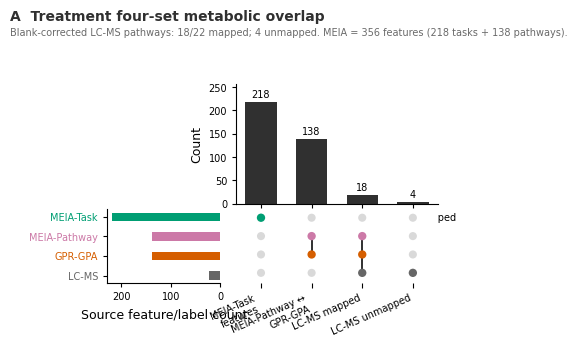

In [4]:
_render_extension_panel('A','treatment_four_set_membership.csv',PANEL_DATA,'panels')

## Figure 6B — gridless treatment pathway-enrichment scatter

,panel,file,rows,columns
0,B,surgery_pathway_scatter.csv,22,7


surgery_pathway_scatter.csv: first three rows


,rank,pathway,enrichment_factor,neg_log10_p,radius,label_top5,coordinate_source
0,1,Selenoamino acid metabolism,2.592521,1.644146,1.610131,True,PRIVATE_ARCHIVE_ROOT/metabolomics_all_analaysi...
1,2,Aspartate and asparagine metabolism,1.944485,1.124603,1.394448,True,PRIVATE_ARCHIVE_ROOT/metabolomics_all_analaysi...
2,3,Glycolysis and Gluconeogenesis,2.592588,0.897395,1.610152,True,PRIVATE_ARCHIVE_ROOT/metabolomics_all_analaysi...


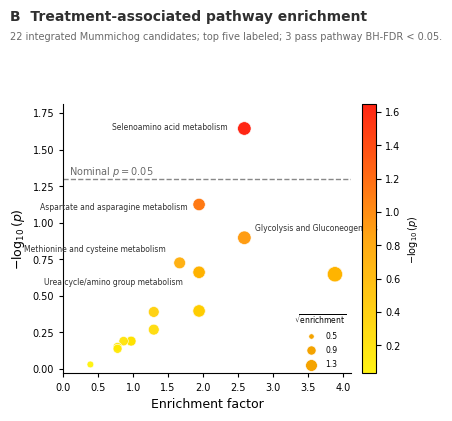

In [5]:
_render_panel_files('B',['surgery_pathway_scatter.csv'],PANEL_DATA,'panels')

### Additional Figure 6F view — all-cell treatment response by metastatic status


## Figure 6C — GPR-GPA versus scKnife pathways: Surgery − Biopsy


,panel,file,rows,columns
0,C,gpr_gpa_vs_scknife_effects.csv,1656,7


gpr_gpa_vs_scknife_effects.csv: first three rows


,comparison,contrast,cell_type,feature,x,y,feature_layer
0,GPR_GPA_vs_scKNIFE,surgery_vs_biopsy,Epithelial,Glycolysis_Gluconeogenesis,-0.311755,-0.277417,Pathway
1,GPR_GPA_vs_scKNIFE,surgery_vs_biopsy,Epithelial,Starch_and_sucrose_metabolism,-0.353714,-0.333537,Pathway
2,GPR_GPA_vs_scKNIFE,surgery_vs_biopsy,Epithelial,Galactose_metabolism,-0.387398,-0.365166,Pathway


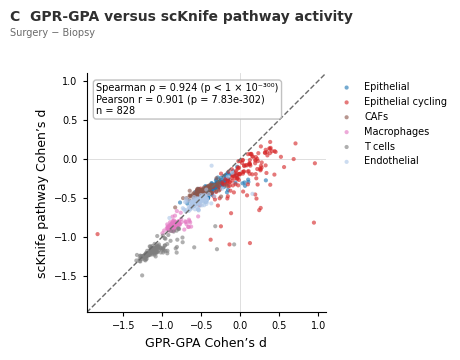

In [6]:
_render_panel_files('C',['gpr_gpa_vs_scknife_effects.csv'],PANEL_DATA,'panels')


## Figure 6D — T-cell glycoconjugate activity: longitudinal decrease and postoperative convergence

The graph-prioritized 29-feature MEIA family is summarized only for visualization by an equal-feature composite. Each feature is centered and scaled using the 14 patient × site T-cell medians, and the fixed transform is then applied to every biopsy/surgery T cell. Boxes and faint points show cells; large P1–P7 dots show patient medians and carry the exact patient-level tests. Metastatic status is shown separately at biopsy and surgery. The GPR-GPA inset is contextual rather than an independent discovery test.

,panel,file,rows,columns
0,D,panel_d_graph_seeds.csv,6,9
1,D,panel_d_meia_joint_enrichment.csv,2,13
2,D,panel_d_meia_tcell_reversal.csv,29,14
3,D,panel_d_gpr_context_reversal.csv,14,8
4,D,panel_d_mechanism_cell_scores.csv.gz,14552,8
5,D,panel_d_mechanism_patient_medians.csv,28,7
6,D,panel_d_mechanism_patient_tests.csv,6,14


panel_d_graph_seeds.csv: first three rows


,program_id,program_name,node_kind,node_name,enrichment_delta_z,decay_weight,source_panel,graph_role,display_order
0,P2,RNA processing / glycosylation precursor metab...,reaction,PMANM,2.260120,1.000000,Figure 5 W program dictionary,mannose-precursor interconversion,0
1,P2,RNA processing / glycosylation precursor metab...,task,GDP-mannose synthesis,2.052667,1.000000,Figure 5 W program dictionary,nucleotide-sugar supply,1
2,P2,RNA processing / glycosylation precursor metab...,reaction,MAN1PT2,2.087963,0.818731,Figure 5 W program dictionary,mannose-precursor interconversion,2


panel_d_meia_joint_enrichment.csv: first three rows


,contrast,method,mechanism,universe_n,top_n,mechanism_features,top_hits,odds_ratio,p_value,fdr,contrast_order,contrast_display,fdr_supported
0,surgery_vs_biopsy,MEIA,M2,356,50,29,14,7.544444,0.000003,0.000006,0,Surgery–Biopsy,True
1,metastatic_vs_nonmetastatic,MEIA,M2,356,50,29,3,0.687398,0.806082,0.989369,1,Metastatic–Non-metastatic,False


...

,cell_id,method,mechanism_score,PatientID,Site,metastatic_status,patient_display,feature_count
0,library4_sample3_AAACCAATCCCTCGCTAGTAGGCT-1,MEIA,0.550520,P3,Surgery,Metastatic,P3,29
1,library4_sample3_AAACGGGCATCACTCGAGTAGGCT-1,MEIA,-0.264717,P3,Surgery,Metastatic,P3,29
2,library4_sample3_AAAGCGAAGTAGCGCAAGTAGGCT-1,MEIA,-0.425212,P3,Surgery,Metastatic,P3,29


panel_d_mechanism_patient_medians.csv: first three rows


,method,PatientID,patient_display,Site,metastatic_status,patient_median,n_cells
0,GPR_GPA,P7,P7,Bx,Non-metastatic,0.031996,404
1,GPR_GPA,P7,P7,Surgery,Non-metastatic,-1.172968,8
2,GPR_GPA,P1,P1,Bx,Non-metastatic,0.019609,101


panel_d_mechanism_patient_tests.csv: first three rows


,method,comparison,site,group_a,group_b,n_group_a,n_group_b,test,statistic,p_value,patient_effect,patient_effect_definition,directional_patients,cellwise_cohens_d
0,MEIA,surgery_vs_biopsy,paired,Surgery,Bx,7,7,exact two-sided Wilcoxon signed-rank,5.0,0.15625,-0.503044,median paired patient-median change (Surgery -...,5.0,-0.903524
1,MEIA,metastatic_vs_nonmetastatic,Bx,Metastatic,Non-metastatic,4,3,exact two-sided Mann-Whitney U,9.0,0.40000,0.936323,difference of patient-median medians (Metastat...,NaN,1.009966
2,MEIA,metastatic_vs_nonmetastatic,Surgery,Metastatic,Non-metastatic,4,3,exact two-sided Mann-Whitney U,6.0,1.00000,-0.124680,difference of patient-median medians (Metastat...,NaN,0.049313


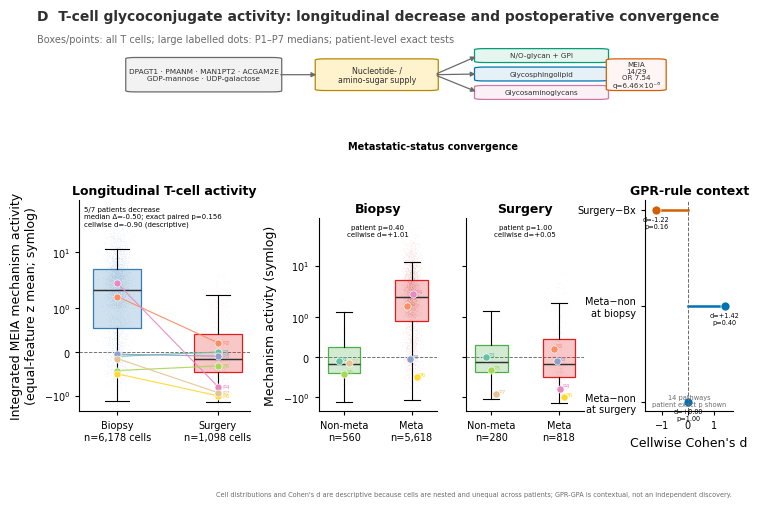

In [7]:
_render_panel_files('D',['panel_d_graph_seeds.csv', 'panel_d_meia_joint_enrichment.csv', 'panel_d_meia_tcell_reversal.csv', 'panel_d_gpr_context_reversal.csv', 'panel_d_mechanism_cell_scores.csv.gz', 'panel_d_mechanism_patient_medians.csv', 'panel_d_mechanism_patient_tests.csv'],PANEL_DATA,'panels')

## Figure 6E — representative baseline-restoration trajectories


,panel,file,rows,columns
0,E,robust_tier3_trajectory_selection.csv,3,10
1,E,robust_tier3_trajectory_values.csv.gz,8113,8


robust_tier3_trajectory_selection.csv: first three rows


,display_order,global_rank,metabolite,display_name,celltype,tier,tier1_replicated_treatment,tier2_recurrence_rebound,tier3_baseline_like_recurrence,selection_rule
0,1,7,2E_heptenoyl_CoA,(2E)-heptenoyl-CoA,CAFs,3,True,True,True,Predefined representative strict Tier-3 candid...
1,2,16,5_ppPur_mRNA,(5)ppPur-mRNA,Epithelial,3,True,True,True,Predefined representative strict Tier-3 candid...
2,3,6,heparan_sulfate_degradation_product_18,"heparan sulfate, degradation product 18",T cells,3,True,True,True,Predefined representative strict Tier-3 candid...


robust_tier3_trajectory_values.csv.gz: first three rows


,cell_id,PatientID,Timepoint,celltype,activity,display_order,metabolite,display_name
0,library4_sample3_AAACCAATCAATACAGAGTAGGCT-1,P3,Surgery,CAFs,0.208884,1,2E_heptenoyl_CoA,(2E)-heptenoyl-CoA
1,library4_sample3_AAACCGGTCCAAAGACAGTAGGCT-1,P3,Surgery,CAFs,0.234621,1,2E_heptenoyl_CoA,(2E)-heptenoyl-CoA
2,library4_sample3_AAACGGGCAATTGAACAGTAGGCT-1,P3,Surgery,CAFs,0.280702,1,2E_heptenoyl_CoA,(2E)-heptenoyl-CoA


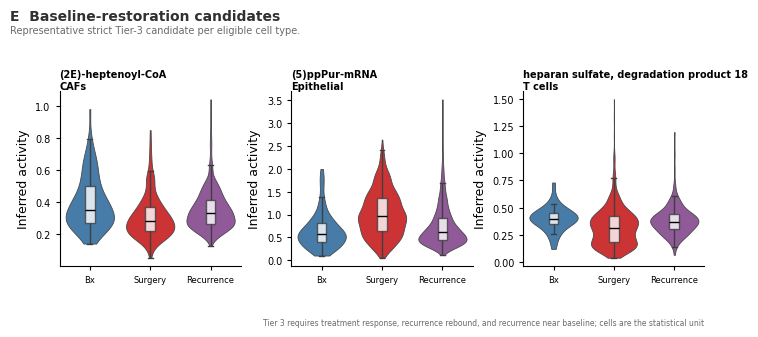

In [8]:
_render_panel_files('E',['robust_tier3_trajectory_selection.csv', 'robust_tier3_trajectory_values.csv.gz'],PANEL_DATA,'panels')


## Figure 6F — exploratory cross-modal comparison: L-threonine


,panel,file,rows,columns
0,F,robust_four_lcms_paired_abundance.csv,14,8
1,F,robust_lcms_treatment_effects.csv,1,13
2,F,robust_dhu_cf30117_t_cells.csv.gz,826,5


robust_four_lcms_paired_abundance.csv: first three rows


,scKNIFE_metabolite,display_name,Feature,Polarity,PatientID,SpecimenID,Timepoint,log2_intensity
0,threonine,L-threonine,pos_120.0613_397.07,positive,P1,CF_06685_1015172,Bx,26.656734
1,threonine,L-threonine,pos_120.0613_397.07,positive,P1,CF_06685_1016015,Surgery,28.465132
2,threonine,L-threonine,pos_120.0613_397.07,positive,P2,CF_16980_1016703,Bx,25.540671


robust_lcms_treatment_effects.csv: first three rows


,display_order,scKNIFE_metabolite,display_name,identity_confidence,identity_rule,Feature,Polarity,log2_fold_change,nominal_p_value,joint_BH_FDR,t_score,treatment_FDR_supported,confidence_label
0,0,threonine,L-threonine,Putative native MS/MS library match,Native library candidate,pos_120.0613_397.07,positive,1.90636,0.002127,0.053533,3.818637,False,Putative native MS/MS library match; MSI level...


robust_dhu_cf30117_t_cells.csv.gz: first three rows


,cell_id,PatientID,Timepoint,celltype,activity
0,library4_sample3_AAACCAATCCCTCGCTAGTAGGCT-1,P3,Surgery,T cells,0.494005
1,library4_sample3_AAACGGGCATCACTCGAGTAGGCT-1,P3,Surgery,T cells,0.406766
2,library4_sample3_AAAGCGAAGTAGCGCAAGTAGGCT-1,P3,Surgery,T cells,0.390556


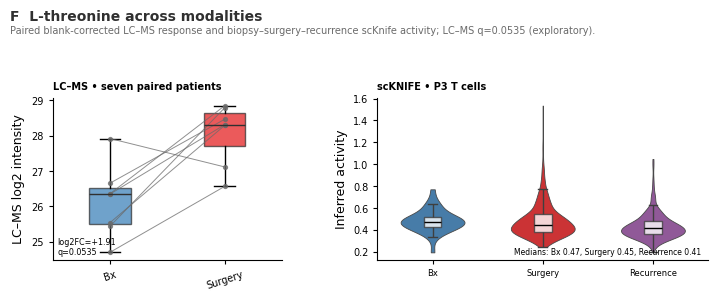

In [9]:
_render_panel_files('F',['robust_four_lcms_paired_abundance.csv', 'robust_lcms_treatment_effects.csv', 'robust_dhu_cf30117_t_cells.csv.gz'],PANEL_DATA,'panels')


## Compiled main figure — rebuilt from live panel data


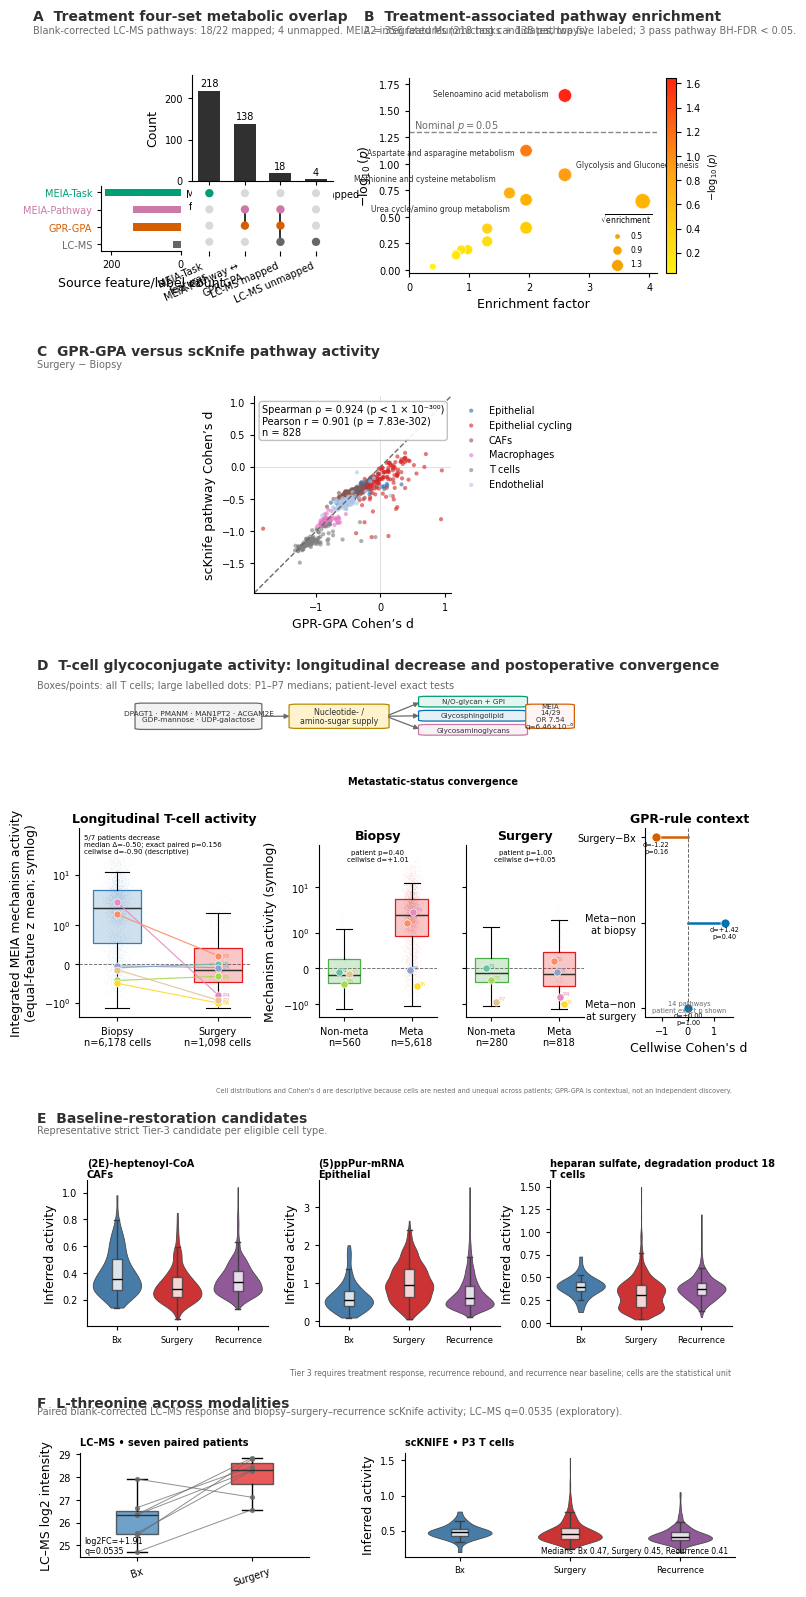

In [10]:
_main_labels=tuple("ABCDEF")
if set(PANEL_DATA)!=set(_main_labels):raise RuntimeError(f"Compiled main figure requires A–F data; found {sorted(PANEL_DATA)}")
_main_data={}
for _label in _main_labels:_main_data.update(PANEL_DATA[_label])
_main_figure=make_figure6_compiled(_main_data)
for _suffix in ("png","pdf"):_main_figure.savefig((ROOT/"outputs")/f"Figure_6.{_suffix}",format=_suffix,dpi=OUTPUT_DPI,facecolor="white",bbox_inches="tight")
plt.figure(_main_figure.number);plt.show();plt.close(_main_figure)